# 03 — Modélisation et évaluation

Les modèles sont entraînés par `make train-clf` et `make train-reg` (GridSearchCV, suivi MLflow). Ce notebook présente les résultats. Le **champion est choisi sur la validation croisée du train**, jamais sur le test.

In [1]:
import pandas as pd
from IPython.display import Image, display

from obesity import config as cfg

T = cfg.path('tables_dir'); F = cfg.path('figures_dir')
display(pd.read_csv(T/'model_comparison.csv'))

,Modèle,Accuracy,F1-Score,Recall,Points forts
0,DecisionTree,0.715,0.710,0.708,"Interprétable, rapide ; tendance au surapprent..."
1,SVM,0.753,0.743,0.746,"Bon compromis biais/variance, écart train/test..."
2,RandomForest,0.785,0.776,0.778,"Robuste, importances des variables"
3,GradientBoosting,0.781,0.775,0.775,"Boosting d'arbres, souvent le plus précis sur ..."
4,MLP,0.732,0.726,0.724,Réseau de neurones ; sensible aux hyperparamèt...


## Classification (pipeline A)
Cinq modèles sont comparés : arbre, SVM et forêt aléatoire, plus deux modèles ajoutés après les premiers résultats (gradient boosting et réseau de neurones MLP). Le gradient boosting et la forêt aléatoire sont à égalité en validation croisée (≈ 0,79) ; le champion est le meilleur en CV, soit le gradient boosting, mais l'écart est dans le bruit. Les scores restent modestes (F1 macro ≈ 0,78) parce que les variables de mode de vie seules expliquent imparfaitement l'IMC : changer d'algorithme n'élimine pas ce plafond.

,model,cv_f1_macro,test_accuracy,test_balanced_accuracy,test_f1_macro,test_accuracy_pm1,test_roc_auc_ovr_macro
0,DecisionTree,0.703,0.715,0.708,0.710,0.864,0.831
1,SVM,0.730,0.753,0.746,0.743,0.880,NaN
2,RandomForest,0.789,0.785,0.778,0.776,0.884,0.961
3,GradientBoosting,0.790,0.781,0.775,0.775,0.884,0.956
4,MLP,0.730,0.732,0.724,0.726,0.872,0.914
5,RandomForest_LEAKAGE,0.937,0.947,0.945,0.946,0.990,0.995


Champion (CV) : GradientBoosting


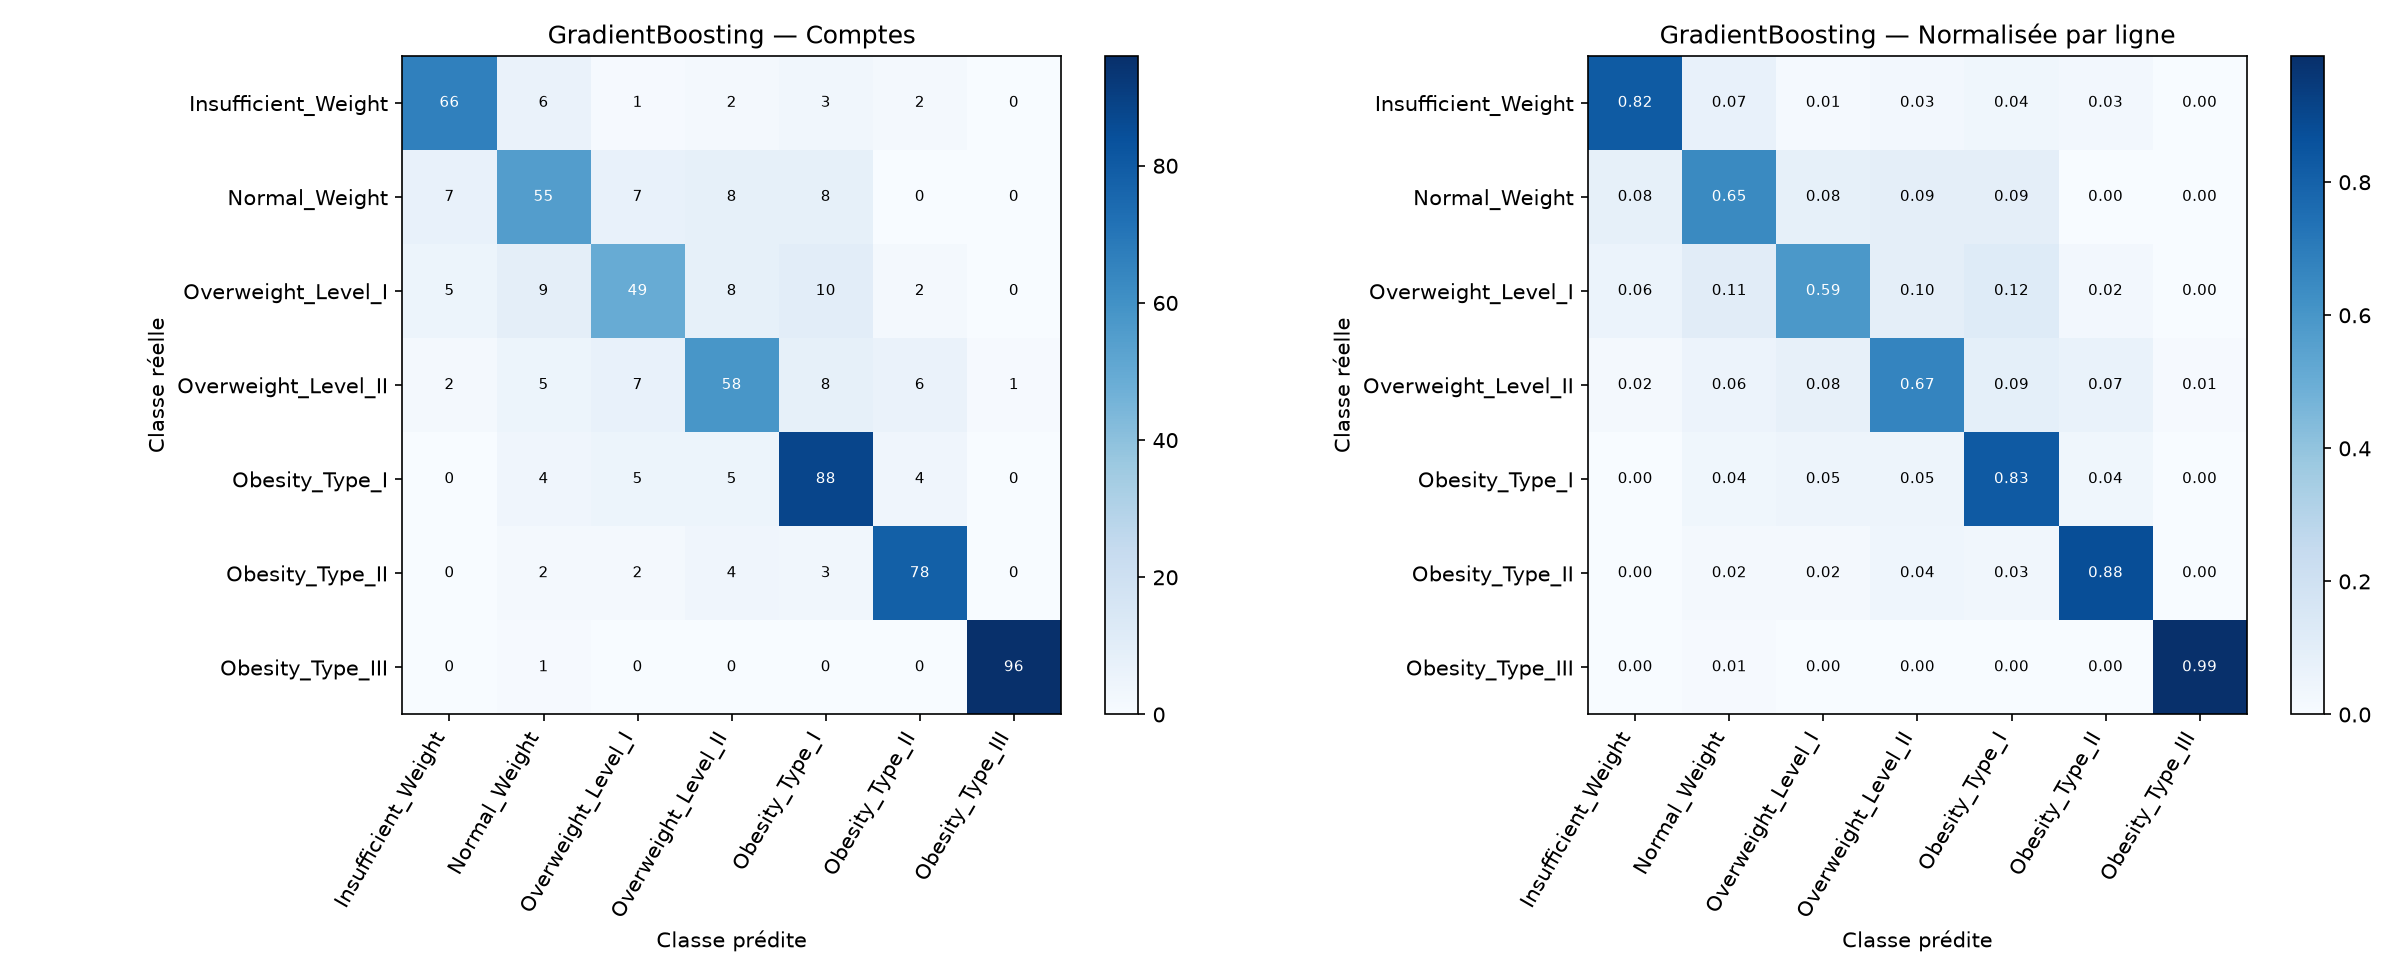

In [2]:
display(pd.read_csv(T/'classification_results.csv')[['model','cv_f1_macro','test_accuracy','test_balanced_accuracy','test_f1_macro','test_accuracy_pm1','test_roc_auc_ovr_macro']].round(3))
champ = pd.read_csv(T/'classification_results.csv').query('~model.str.endswith("_LEAKAGE")').sort_values('cv_f1_macro').iloc[-1]['model']
print('Champion (CV) :', champ)
display(Image(str(F/f'model_cm_{champ}.png'), width=900))

## SVM : One-vs-Rest ou One-vs-One ?
Avec 7 classes, un SVM (binaire par nature) doit être étendu. Deux stratégies : **One-vs-Rest** (une machine par classe contre toutes les autres, 7 machines) et **One-vs-One** (une machine par paire de classes, 21 machines). Dans scikit-learn, `SVC` utilise toujours One-vs-One en interne ; `decision_function_shape='ovr'` ne change que la forme de la fonction de décision, pas la prédiction. On compare donc les trois variantes aux meilleurs hyperparamètres, en validation croisée sur le train (le test n'est pas réutilisé).

In [3]:
from obesity.svm_compare import compare

display(compare())

,variante,f1_macro_cv,ecart_type
0,"SVC (decision_function_shape='ovr', OvO interne)",0.7296,0.0365
1,OneVsRestClassifier(SVC),0.7361,0.0314
2,OneVsOneClassifier(SVC),0.7301,0.0405


## Run de référence « fuite »
Avec `Weight` et `Height`, les scores grimpent (voir tableau) : c'est la preuve de la fuite. Ce run est tagué `leakage_reference=true` et **n'est jamais un modèle final**.

In [4]:
display(pd.read_csv(T/'leakage_comparison.csv').round(3))

,model,test_accuracy,test_f1_macro,test_accuracy_pm1
0,RandomForest,0.785,0.776,0.884
1,RandomForest_LEAKAGE,0.947,0.946,0.990


## Régression (pipeline B)
Linear, Ridge et Lasso donnent des résultats quasi identiques (RMSE ≈ 18 kg, R² ≈ 0,52) : peu de colinéarité (VIF max ≈ 7) et peu de sur-ajustement. L'hétéroscédasticité est marquée (test de Breusch-Pagan) ; `log(Weight)` améliore légèrement le test.

Quatre modèles **non linéaires** sont ensuite testés (forêt aléatoire, gradient boosting, SVR, réseau de neurones MLP). Ils réduisent fortement l'erreur : la forêt aléatoire, meilleure en validation croisée, descend à un RMSE d'environ 9,6 kg (R² ≈ 0,87). Attention : une grande part de ce gain vient des lignes synthétiques, quasi copies de lignes d'entraînement (voir notebook 04).

,model,train_mae,train_rmse,train_r2,test_mae,test_rmse,test_r2
0,LinearRegression,14.101,17.512,0.554,14.206,18.016,0.524
1,Ridge,14.133,17.524,0.553,14.228,18.028,0.523
2,Lasso,14.143,17.536,0.552,14.224,18.034,0.523
3,RandomForest,1.924,3.187,0.985,5.680,9.613,0.865
4,GradientBoosting,3.762,5.460,0.957,6.682,10.213,0.847
5,SVR,4.815,6.402,0.940,7.870,11.661,0.801
6,MLP,4.132,5.857,0.950,7.436,11.303,0.813


,Unnamed: 0,value
0,test_mae,13.918
1,test_rmse,17.714
2,test_r2,0.540


,variable,vif
0,Age,1.88
1,FCVC,1.15
2,NCP,1.11
3,CH2O,1.12
4,FAF,1.23
5,TUE,1.16
6,Height,2.25
7,family_history_with_overweight_yes,1.29
8,FAVC_yes,1.23
9,SMOKE_yes,1.05


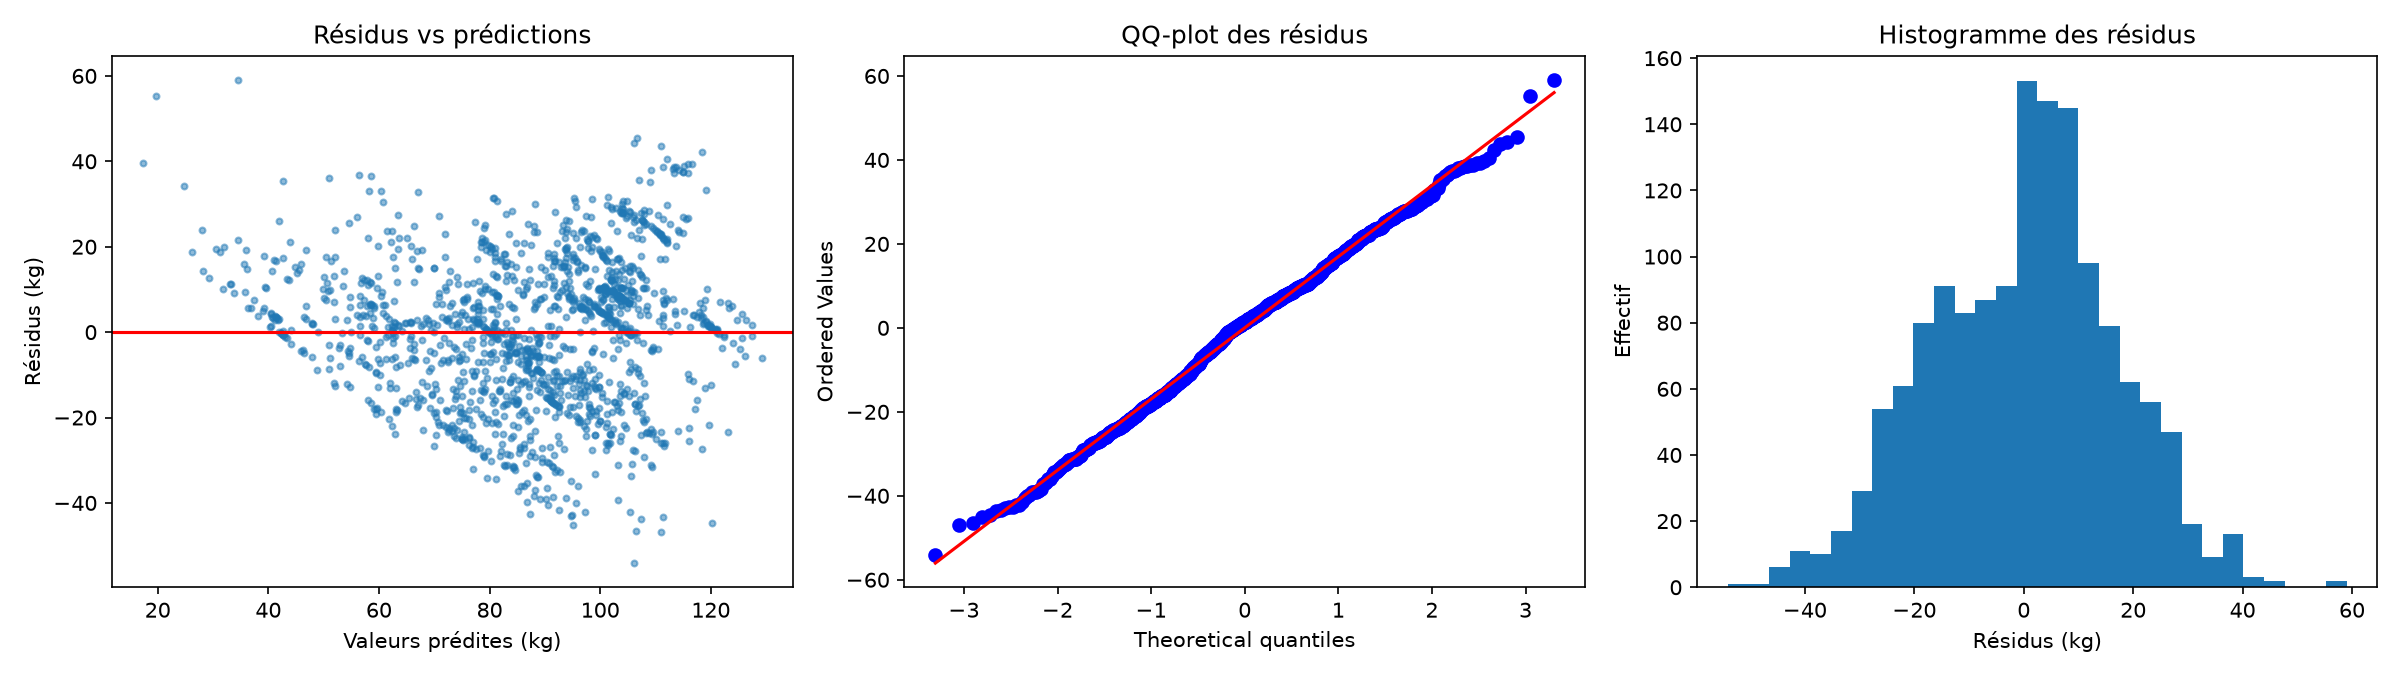

In [5]:
display(pd.read_csv(T/'regression_comparison.csv'))
display(pd.read_csv(T/'regression_log_weight.csv').round(3))
display(pd.read_csv(T/'vif.csv').round(2))
display(Image(str(F/'model_residuals_ols.png'), width=900))

## Cohérence (pipeline C)
Peut-on retrouver la classe en prédisant le poids puis en calculant `IMC = Weight_pred / Height²` ? Avec la régression linéaire (erreur ≈ 18 kg), la classe dérivée était très mauvaise (accuracy 0,23, ±1 classe 0,71). Avec la régression champion non linéaire, elle monte nettement (voir tableau), mais reste en dessous de la classification directe.

,accuracy,accuracy_pm1,f1_macro
A_classifieur,0.781,0.884,0.775
C_poids_predit,0.616,0.909,0.620


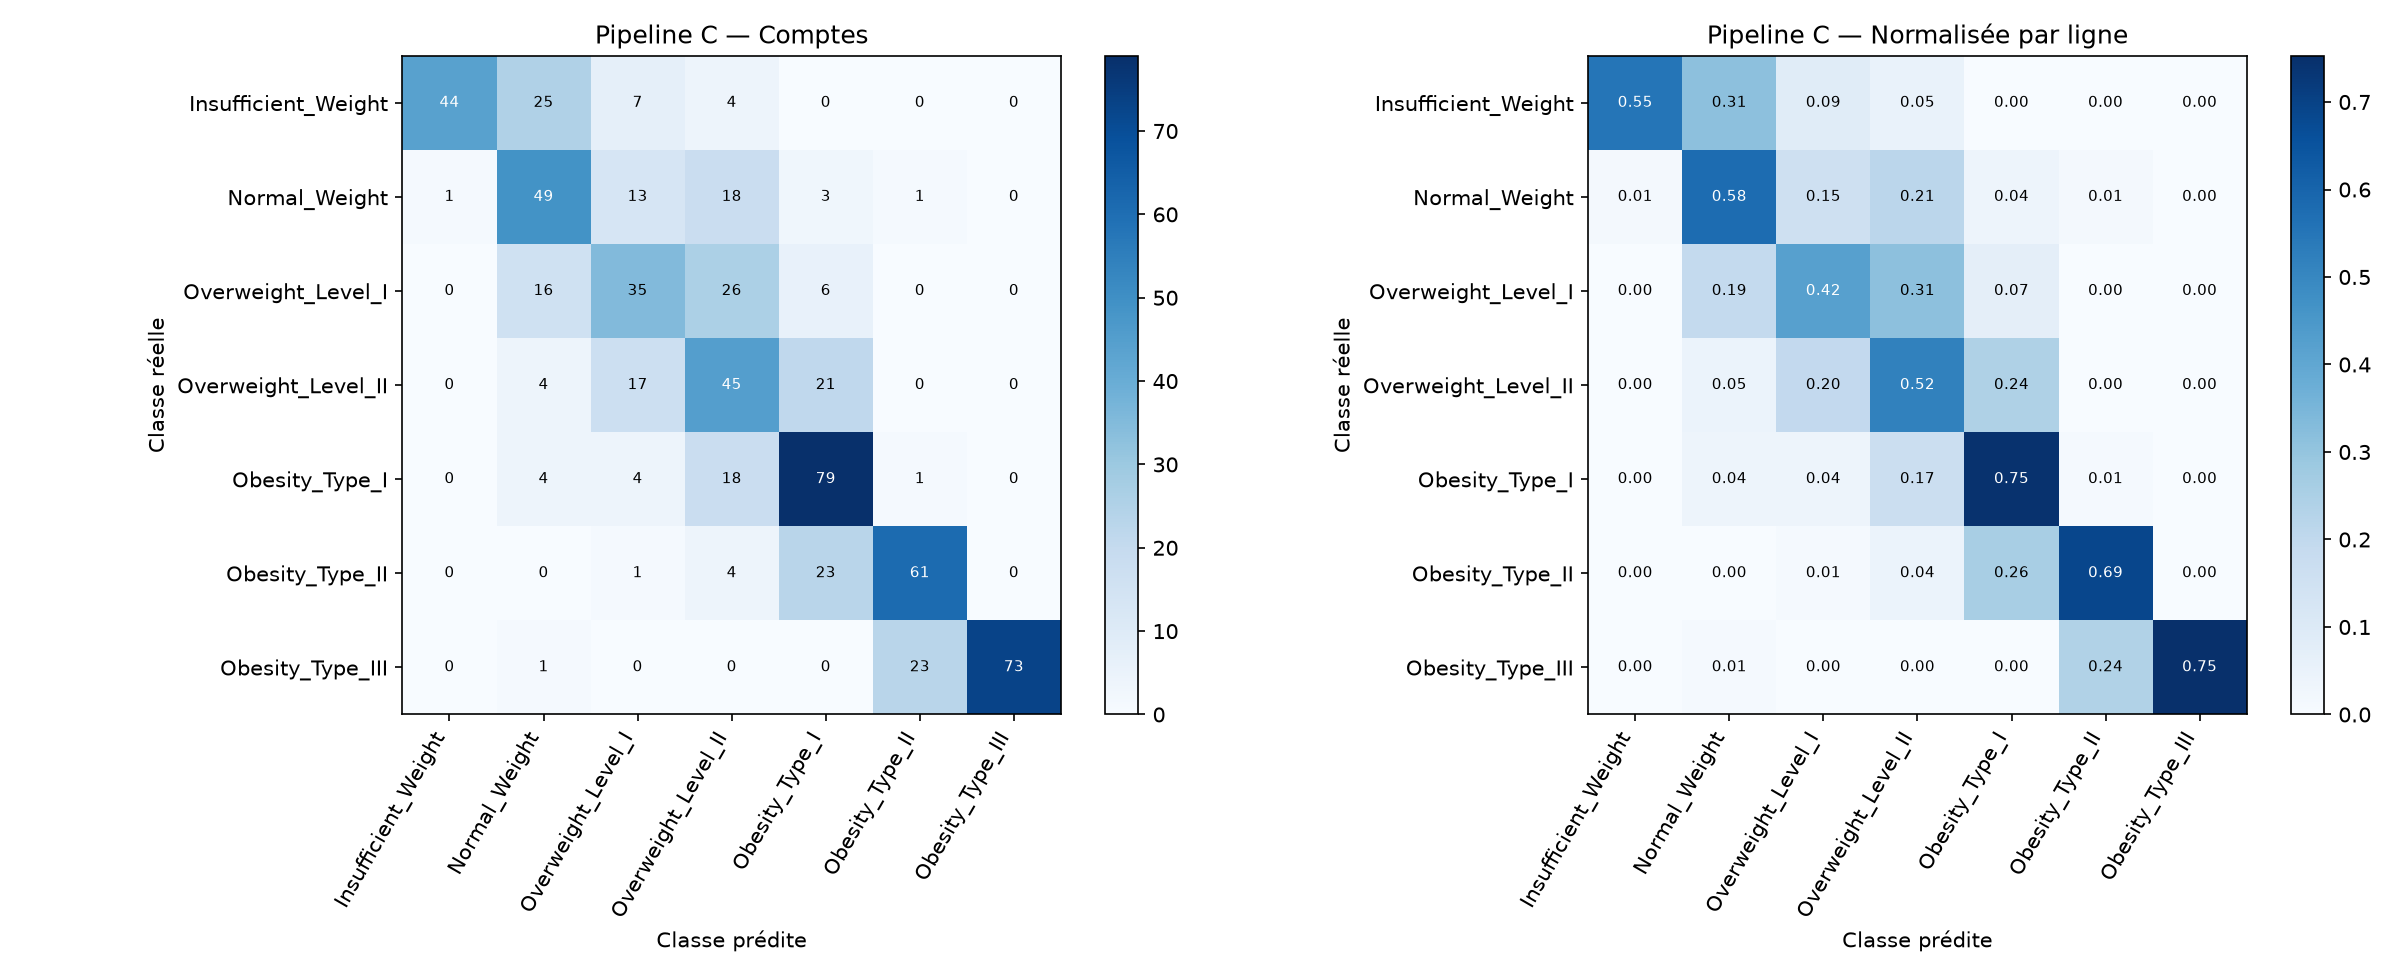

In [6]:
display(pd.read_csv(T/'consistency.csv', index_col=0)[['accuracy','accuracy_pm1','f1_macro']].round(3))
display(Image(str(F/'model_cm_pipeline_C.png'), width=900))